In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import re
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from collections import defaultdict


21.374856034068436
2.753802905353446
10


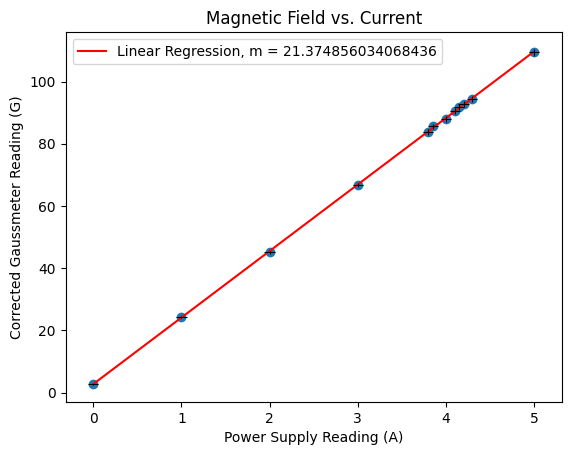

In [13]:
x = np.array([0, 1, 2, 3, 3.8, 3.85, 4, 4.1, 4.15, 4.2, 4.3, 5])
y_raw = [3.7, 26.2, 47.5, 70.0, 87.5, 89.4, 91.9, 94.6, 95.9, 96.8, 98.6, 114.0]

mag = 99.69
calib = np.array([104.0, -102.2])

# Calibration
z = np.mean(calib)
z_unc = np.sqrt(0.2**2 + 0.02**2) / 2

calib_mean = np.mean(np.abs(calib))
s = calib_mean / mag

calib_mean_unc = np.sqrt(0.2**2 + 0.02**2) / 2
s_unc = s * np.sqrt(
    (calib_mean_unc / calib_mean)**2 + 0.01**2
)

# Corrected field
y = (y_raw - z) / s

# Standard uncertainties
xerr = 0.2 / np.sqrt(12)
yerr = np.sqrt(
    (y * s_unc / s)**2
    + (0.2**2 + z_unc**2) / s**2
)

x_line = np.linspace(np.min(x),np.max(x),200)
m, b = np.polyfit(x, y, 1)

y_fit = m * x + b
chi2 = np.sum(((y - y_fit) / yerr)**2)
dof = len(y) - 2

print(m)
print(chi2)
print(dof)

plt.figure()
plt.title('Magnetic Field vs. Current')
plt.ylabel('Corrected Gaussmeter Reading (G)')
plt.xlabel('Power Supply Reading (A)')
plt.plot(x_line, m * x_line + b, color='red', label=f'Linear Regression, m = {m}')
plt.scatter(x,y)
plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', ecolor='black', linewidth=0.75)
plt.legend()
plt.show()

In [9]:
def find_amp(G):
    return (G - b) / m

find_amp(80)

np.float64(3.613325856593852)

In [92]:
file = "/Users/elliottchalcraft/Documents/2026-27/8.13/jlab/relativistic_dynamics/data/raw/calibration/2026-10-14/20261014_background_calibration.Spe"

def get_data(file):
    df = pd.read_csv(file,header=None)

    counts = [int(x) for x in df.iloc[12:2060,0]]

    t = int(df.iloc[9,0].split()[0])
    return np.sum(counts), t

def sig_rate(N, t, res=0.01):
    sig_N = np.sqrt(N)
    sig_t = res**2 / np.sqrt(12)
    return (N / t) * np.sqrt((sig_N / N)**2 + (sig_t / t)**2)

counts, t = get_data(file)
bkg_rate = counts / t
bkg_error = sig_rate(counts, t)

print(bkg_rate)


0.22785108388312914


In [101]:
folder = Path("/Users/elliottchalcraft/Documents/2026-27/8.13/jlab/relativistic_dynamics/data/processed/velocity_sweep_sep/120")

rates = {}
errors = {}

## extract counts and time from .spe file
def get_data(file):
    df = pd.read_csv(file,header=None)

    counts = [int(x) for x in df.iloc[12:2060,0]]

    t = int(df.iloc[9,0].split()[0])
    return np.sum(counts), t
    # return np.sum(counts)/t, np.sqrt(np.sum(counts))/t

## calculate error on voltage according to multimeter resolution and manual (sys only)
def sig_V(V):
    return (0.003 * V + 0.001) / np.sqrt(3)

## calculate error on count rate (stat in N, sys in t)
def sig_rate(N, t, res=0.01):
    sig_N = np.sqrt(N)
    sig_t = res**2 / np.sqrt(12)
    return (N / t) * np.sqrt((sig_N / N)**2 + (sig_t / t)**2)


pattern = re.compile(r"Vsel([\dp]+)kV")
rates = defaultdict(list)

for file in sorted(folder.glob("*.Spe")):
    m = pattern.search(file.name)
    if m is None:
        print(f"Skipping: {file.name}")
        continue
    key = float(m.group(1).replace("p", "."))
    counts, t = get_data(file)
    rates[key] = counts / t
    errors[key] = sig_rate(counts, t)

x = []
y = []
yerrs = []

for key, value in sorted(rates.items()):
    x.append(key)
    y.append(value)
for key, value in sorted(errors.items()):
    yerrs.append(value)

x = np.array(x,dtype=float)
xerrs  = [sig_V(V) for V in x]
y = np.array(y,dtype=float)
yerrs = np.array(yerrs,dtype=float)

print(x)
print(xerrs)
print(y)
print(yerrs)

# print(tot_counts)
# print('')
# print(tot_counts[4.25] - tot_counts[4.0])
# print(tot_counts[4.25] - tot_counts[4.5])

[4.  4.3 4.5 4.6 4.7 4.8 4.9 5.  5.1 5.3 5.8]
[np.float64(0.007505553499465136), np.float64(0.008025168741735799), np.float64(0.008371578903249573), np.float64(0.008544783984006462), np.float64(0.008717989064763352), np.float64(0.008891194145520238), np.float64(0.009064399226277126), np.float64(0.009237604307034013), np.float64(0.0094108093877909), np.float64(0.009757219549304677), np.float64(0.010623244953089115)]
[1.56896552 2.10752688 3.07594937 3.41262136 4.05925926 4.29126214
 4.27439024 4.38257576 4.06097561 2.5617284  1.41666667]
[0.08223614 0.10644618 0.1395279  0.12870945 0.17340296 0.20411452
 0.16144149 0.12884357 0.15735961 0.1257503  0.07882544]


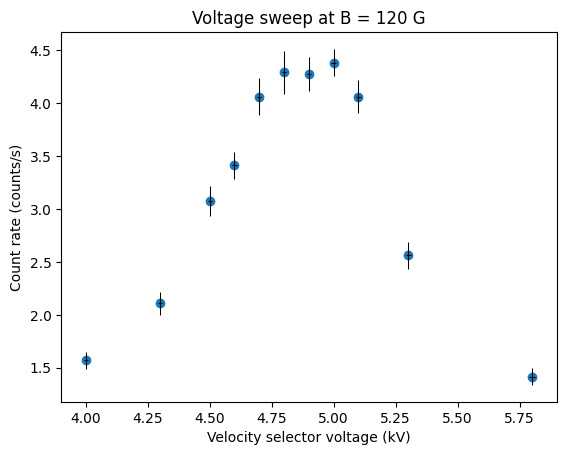

In [102]:
plt.figure()
plt.errorbar(x, y, yerr=yerrs, xerr=xerrs, fmt='none', ecolor='black', linewidth=0.75)
plt.scatter(x,y)
# plt.plot(x,y)
plt.xlabel('Velocity selector voltage (kV)')
plt.ylabel('Count rate (counts/s)')
plt.title('Voltage sweep at B = 120 G')
plt.show()

In [103]:
def trapezoid(x, center=0, slope=1, width=1, height=1, offset=0):
    """
    For given array x, returns a (symmetric) trapezoid with plateau at y=h (or -h if 
    slope is negative), centered at center value of "x".
    Note: Negative widths and heights just converted to 0

    Parameters
    ----------
    x : array_like
        array of x values at which the trapezoid should be evaluated
    center : float
        x coordinate of the center of the (symmetric) trapezoid
    slope : float
        slope of the sides of the trapezoid
    width : float
        width of the plateau of the trapezoid
    height : float
        (positive) vertical distance between the base and plateau of the trapezoid
    offset : array_like
        vertical shift (either single value or the same shape as x) to add to y before returning

    Returns
    -------
    y : array_like
        y value(s) of trapezoid with above parameters, evaluated at x

    """
    
    # ---------- input checking ----------
    if width < 0: width = 0
    if height < 0: height = 0

    x = np.asarray(x)

    slope_negative = slope < 0
    slope = np.abs(slope)  #  Do all calculations with positive slope, invert at end if necessary

    # ---------- Calculation ----------
    y = np.zeros_like(x)
    mask_left = x - center < -width/2.0
    mask_right = x - center > width/2.0

    y[mask_left] = slope*(x[mask_left] - center + width/2.0)
    y[mask_right] = -slope*(x[mask_right] - center - width/2.0)

    y += height     # Shift plateau up to y=h
    y[y < 0] = 0    # cut off below zero (so that trapezoid flattens off at "offset")

    if slope_negative: y = -y          # invert non-plateau

    return y + offset

PARAM_NAMES = ["center", "slope", "width", "height", "offset"]
 
 
def fit_trapezoid(x, y, yerr=None, p0=None, plot=True, ax=None):
    """Fit `trapezoid` to (x, y, yerr) with scipy's curve_fit.
 
    Parameters
    ----------
    x, y : array_like
    yerr : array_like, float or None
        1-sigma errors on y (scalar = same error for every point).
    p0 : sequence of 5 floats, optional
        Initial guess [center, slope, width, height, offset]. Auto-generated if None.
    plot : bool
        Plot the data and the fit.
    ax : matplotlib Axes, optional
        Axes to draw on (new figure if None).
 
    Returns
    -------
    popt, perr, chi2_red, pcov
        Best-fit [center, slope, width, height, offset], their 1-sigma errors,
        reduced chi-squared (nan if no yerr), and the full covariance matrix.
    """
    x = np.asarray(x, dtype=float)   # float, so np.zeros_like in trapezoid isn't int
    y = np.asarray(y, dtype=float)
    have_err = yerr is not None
    sigma = np.broadcast_to(np.asarray(yerr, dtype=float), x.shape) if have_err else None
 
    xr, yr = np.ptp(x), np.ptp(y)
 
    if p0 is None:
        offset0 = y.min()
        # centre of the points lying above half-maximum
        above = y > offset0 + 0.5 * yr
        center0 = x[above].mean() if above.any() else x[np.argmax(y)]
        p0 = [center0, yr / (0.4 * xr), 0.2 * xr, yr, offset0]
 
    #           center      slope  width   height  offset
    lower = [x.min(),     1e-9,   0.0,    0.0,    -np.inf]
    upper = [x.max(),    np.inf,  2 * xr, np.inf,  np.inf]
 
    popt, pcov = curve_fit(trapezoid, x, y, p0=p0, sigma=sigma,
                           absolute_sigma=have_err, bounds=(lower, upper),
                           maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
 
    dof = len(x) - len(popt)
    if have_err and dof > 0:
        chi2 = np.sum(((y - trapezoid(x, *popt)) / sigma) ** 2)
        chi2_red = np.sum(((y - trapezoid(x, *popt)) / sigma) ** 2) / dof
    else:
        chi2_red = np.nan
 
    if plot:
        if ax is None:
            _, ax = plt.subplots(figsize=(7, 4.5))
        xs = np.linspace(x.min() - 0.1 * xr, x.max() + 0.1 * xr, 1000)
        if have_err:
            ax.scatter(x,y)
            ax.errorbar(x, y, yerr=yerrs, xerr=xerrs, fmt='none', ecolor='black', linewidth=0.75)
        else:
            ax.plot(x, y, "ko", label="Data")
        label = "Trapezoid fit"
        if not np.isnan(chi2_red):
            label += f" ($\chi^2$/dof = {chi2:.2f} / {dof:.2f})"
        ax.plot(xs, trapezoid(xs, *popt), "r-", lw=0.75, label=label)
        ax.set_xlabel("Velocity Selector Voltage (kV)")
        ax.set_ylabel("Count Rate (counts/s)")
        ax.set_title("Velocity sweep at B = 80 G")
        ax.legend()
        ax.figure.tight_layout()
        plt.show()
 
    return popt, perr, chi2_red, pcov

<>:118: SyntaxWarning: invalid escape sequence '\c'
<>:118: SyntaxWarning: invalid escape sequence '\c'
/var/folders/56/k05x6nps32gf06_jxz4sq60m0000gn/T/ipykernel_90002/3658020514.py:118: SyntaxWarning: invalid escape sequence '\c'
  label += f" ($\chi^2$/dof = {chi2:.2f} / {dof:.2f})"


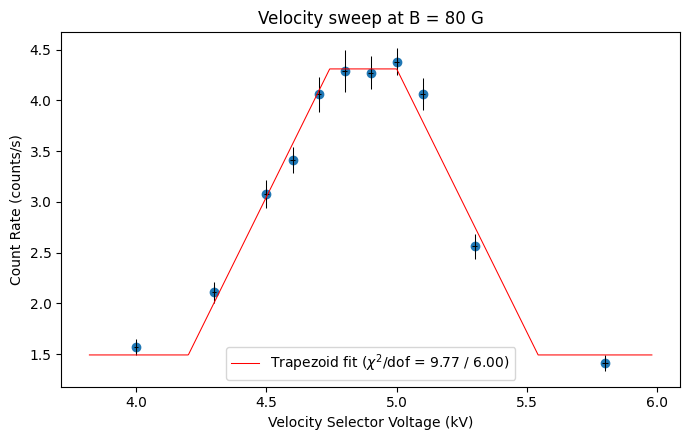

center   = 4.8713 ± 0.0115
slope    = 5.1900 ± 0.3970
width    = 0.2573 ± 0.0558
height   = 2.8175 ± 0.1067
offset   = 1.4922 ± 0.0569
reduced chi^2 = 1.63
plateau level = 4.3097


In [104]:
popt, perr, chi2_red, pcov = fit_trapezoid(x, y, yerrs)
for n, v, e in zip(PARAM_NAMES, popt, perr):
        print(f"{n:8s} = {v:.4f} ± {e:.4f}")
print(f"reduced chi^2 = {chi2_red:.2f}")
print(f"plateau level = {popt[3] + popt[4]:.4f}")

In [42]:
B = np.array([80, 89.4, 91.9, 100, 110, 120])

mag = 99.69
calib = [[104.0, -102.2], [106.0, -103.6], [105.0, -105.4], [104.0, -102.2], [105.1, -106.2], [107.3, -107.4]]

z = np.array([np.mean(np.array(pair)) for pair in calib])                        #zero offset
s = np.array([np.sum(np.abs(np.array(pair))) / (2 * mag) for pair in calib])     #scale

sigma_z = np.sqrt(0.02**2 + 0.02**2) / 2
sigma_s = np.sqrt((0.02**2 + 0.02**2)/(2*mag)**2 + (0.01*s)**2)
sigma_B = m * 0.2
print(sigma_B)

B_corrected = (B - z) / s     #get true B from offset and scale
Berr = np.sqrt(sigma_B**2 + sigma_z**2 + B_corrected**2 * sigma_s**2) / np.abs(s)   
                             # Gauss
V = np.array([2.6688, 3.2185, 3.3592, 3.7834, 4.2964, 4.8713])      # kV
Verr = np.array([0.0121, 0.0145, 0.0086, 0.0112, 0.0142, 0.0115])
d = 0.180                                                           # cm
derr = 0.003

E = V / d * 1000 * 3.336e-3
Eerr = E * np.sqrt((Verr/V)**2 + (derr/d)**2)

beta = E / B_corrected
betaerr = beta * np.sqrt((Eerr/E)**2 + (Berr/B_corrected)**2)

print(B_corrected)
# print(Berr)
# print(beta)
# print(betaerr)

4.274971206813688
[ 76.48379243  83.8994084   87.27613118  95.82229874 104.31357785
 111.48378668]


In [39]:
model_x = np.linspace(0,np.max(B_corrected),1000)

mc2 = 8.18727e-7        # ergs
rho = 40.6 / 2          # cm
e = 4.80298e-10         # statcoloumbs
c = 2.99792458e10

sig_rho = 0.2

def model_nonrel(x):
    m = (e * rho) / mc2
    return m * x

def model_rel(x):
    k = e * rho * x / mc2
    return k / np.sqrt(1 + k**2)

def em_nonrel(B, beta):
    return c**2 * beta / (B * rho)

def em_err_nonrel(B, beta):
    em = em_nonrel(B, beta)
    return em * np.sqrt((betaerr/beta)**2 + (Berr/B)**2 + (sig_rho/rho)**2)

def em_rel(B, beta):
    return c**2 * beta / (B * rho) / np.sqrt(1 - beta**2)

def em_err_rel(B, beta):
    em = em_rel(B, beta)
    return em * np.sqrt((betaerr/(beta*(1-beta**2)))**2 + (Berr/B)**2 + (sig_rho/rho)**2)

In [56]:
em_nonrel_val = em_nonrel(B_corrected, beta)
em_nonrel_sig = em_err_nonrel(B_corrected, beta)

em_rel_val = em_rel(B_corrected, beta)
em_rel_sig = em_err_rel(B_corrected, beta)

def bestem(em, sig):
    weights = 1 / sig**2
    em_best = np.sum(weights * em) / np.sum(weights)
    sig_best = 1 / np.sqrt(np.sum(weights))
    prob_err = 0.6745 * sig_best

    chi2 = np.sum(((em - em_best) / sig)**2)
    dof = len(em) - 1

    print(em_best)
    print(sig_best)
    print(prob_err)
    print(chi2)
    print(dof)

    return em_best, sig_best, prob_err, chi2, dof

bestem(em_nonrel_val, em_nonrel_sig)
print('')
bestem(em_rel_val, em_rel_sig)

print(e/mc2 * c**2)

3.4134048241586214e+17
9201874215628306.0
6206664158441292.0
5.434218925228933
5

5.115535501425735e+17
2.4062858393941308e+16
1.6230397986713412e+16
0.667774795743024
5
5.2724573006256794e+17


3.4134048241586214e+17
9201874215628306.0
6206664158441292.0
5.434218925228933
5
5.115535501425735e+17
2.4062858393941308e+16
1.6230397986713412e+16
0.667774795743024
5


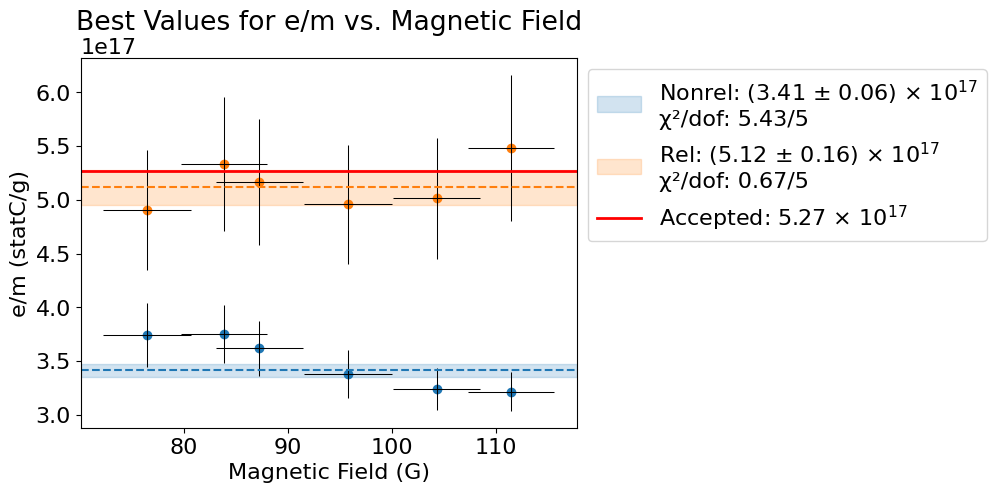

In [75]:
plt.figure()

plt.rcParams.update({'font.size': 16})

plt.scatter(B_corrected, em_nonrel(B_corrected, beta))
plt.errorbar(B_corrected, em_nonrel(B_corrected, beta), yerr=em_err_nonrel(B_corrected, beta), xerr=Berr, fmt='none', ecolor='black', linewidth=0.75)

plt.scatter(B_corrected, em_rel(B_corrected, beta))
plt.errorbar(B_corrected, em_rel(B_corrected, beta), yerr=em_err_rel(B_corrected, beta), xerr=Berr, fmt='none', ecolor='black', linewidth=0.75)

plt.xlabel('Magnetic Field (G)')
plt.ylabel('e/m (statC/g)')

y_best_nonrel = bestem(em_nonrel_val, em_nonrel_sig)
y_best_rel = bestem(em_rel_val, em_rel_sig)

plt.axhline(y=y_best_nonrel[0], linestyle='--')

plt.axhspan(y_best_nonrel[0] - y_best_nonrel[2], y_best_nonrel[0] + y_best_nonrel[2],
            color='tab:blue', alpha=0.2,
            label=f'Nonrel: ({y_best_nonrel[0]/1e17:.2f} ± {y_best_nonrel[2]/1e17:.2f}) × $10^{{17}}$\n'
            f'χ²/dof: {y_best_nonrel[3]:.2f}/{y_best_nonrel[4]}')

plt.axhline(y=y_best_rel[0], linestyle='--',color='tab:orange')

plt.axhspan(y_best_rel[0] - y_best_rel[2], y_best_rel[0] + y_best_rel[2],
            color='tab:orange', alpha=0.2,
            label=f'Rel: ({y_best_rel[0]/1e17:.2f} ± {y_best_rel[2]/1e17:.2f}) × $10^{{17}}$\n'
            f'χ²/dof: {y_best_rel[3]:.2f}/{y_best_rel[4]}')

plt.axhline(y=e/mc2 * c**2, linestyle='-',color='red',lw='2',
            label=f'Accepted: {e/mc2 * c**2/1e17:.2f} × $10^{{17}}$')

plt.legend(bbox_to_anchor=(1, 1),loc='upper left')

plt.title('Best Values for e/m vs. Magnetic Field')

plt.show()

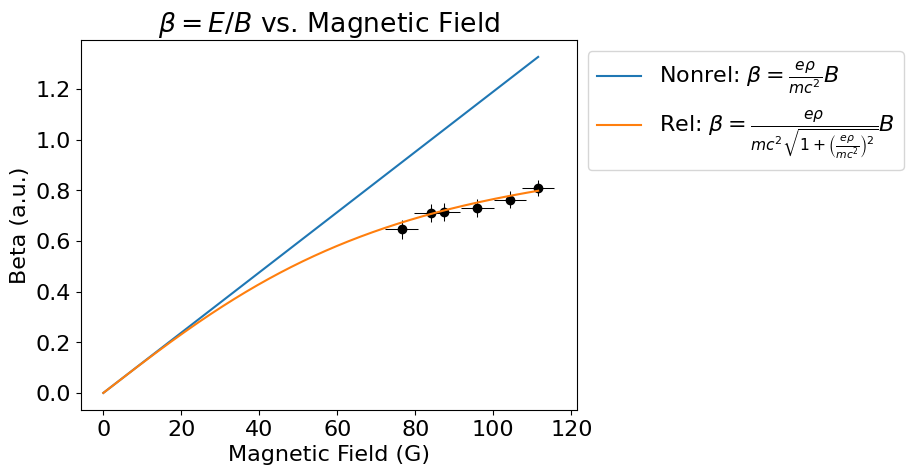

In [85]:
plt.figure()

plt.title(r'$\beta=E/B$ vs. Magnetic Field')
plt.scatter(B_corrected, beta,color='black')
plt.errorbar(B_corrected, beta, yerr=betaerr, xerr=Berr, fmt='none', ecolor='black', linewidth=0.75)
plt.plot(model_x, model_nonrel(model_x),label=r'Nonrel: $\beta=\frac{e\rho}{mc^2}B$',color='tab:blue')
plt.plot(model_x, model_rel(model_x),label=r'Rel: $\beta=\frac{e\rho}{mc^2\sqrt{1+\left(\frac{e\rho}{mc^2}\right)^2}}B$',color='tab:orange')
plt.xlabel('Magnetic Field (G)')
plt.ylabel('Beta (a.u.)')

plt.legend(bbox_to_anchor=(1, 1),loc='upper left')
plt.show()

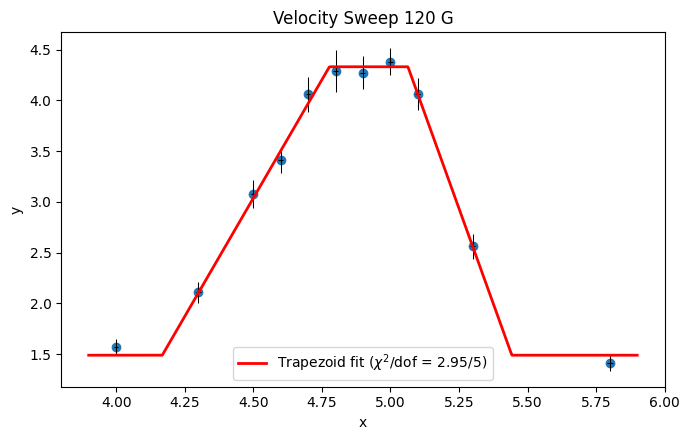

x_start        = 4.1682 ± 0.0343
rise_width     = 0.6096 ± 0.0610
plateau_width  = 0.2862 ± 0.0508
fall_width     = 0.3790 ± 0.0529
height         = 2.8413 ± 0.1067
baseline       = 1.4896 ± 0.0569
chi^2  = 2.95
dof = 5.0000
4.920898438496838


In [142]:
def trapezoid(x, x_start, rise_width, plateau_width, fall_width, height, baseline):
    """Trapezoid: baseline -> ramps up over rise_width -> flat plateau -> ramps down."""
    x = np.asarray(x, dtype=float)
    x1 = x_start
    x2 = x1 + rise_width
    x3 = x2 + plateau_width
    x4 = x3 + fall_width

    y = np.full_like(x, baseline)
    rise = (x >= x1) & (x < x2)
    flat = (x >= x2) & (x <= x3)
    fall = (x > x3) & (x <= x4)

    y[rise] = baseline + height * (x[rise] - x1) / rise_width
    y[flat] = baseline + height
    y[fall] = baseline + height * (x4 - x[fall]) / fall_width
    return y


def fit_trapezoid(x, y, yerr, p0=None, plot=True):
    """Fit a trapezoid to (x, y, yerr) and optionally plot against the data.

    Returns (popt, perr, chi2_red) with parameters ordered as
    [x_start, rise_width, plateau_width, fall_width, height, baseline].
    """
    x, y, yerr = map(np.asarray, (x, y, yerr))

    if p0 is None:
        xr = x.max() - x.min()
        p0 = [x.min(), 0.25 * xr, 0.25 * xr, 0.5 * xr,
              y.max() - y.min(), y.min()]

    # widths must be positive; height/baseline unconstrained
    lower = [x.min() - xr_pad(x), 1e-3, 0.0, 1e-3, 0.0, -np.inf]
    upper = [x.max(), np.ptp(x) * 2, np.ptp(x) * 2, np.ptp(x) * 2, np.inf, np.inf]

    popt, pcov = curve_fit(trapezoid, x, y, p0=p0, sigma=yerr,
                           absolute_sigma=True, bounds=(lower, upper),
                           maxfev=20000)
    perr = np.sqrt(np.diag(pcov))

    dof = len(x) - len(popt)
    chi2 = np.sum(((y - trapezoid(x, *popt)) / yerr) ** 2)
    # chi2_red = chi2 / dof if dof > 0 else np.nan

    if plot:
        xs = np.linspace(x.min() - 0.1, x.max() + 0.1, 1000)
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.scatter(x,y)
        ax.errorbar(x, y, yerr=yerrs, xerr=xerrs, fmt='none', ecolor='black', linewidth=0.75)
        # ax.errorbar(x, y, yerr=yerr, ecolor='black')
        ax.plot(xs, trapezoid(xs, *popt), "r-", lw=2,
                label=f"Trapezoid fit ($\\chi^2$/dof = {chi2:.2f}/{dof:.0f})")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.legend()
        ax.set_title('Velocity Sweep 120 G')
        fig.tight_layout()
        plt.show()

    return popt, perr, dof, chi2


def xr_pad(x):
    return np.ptp(x)  # allow the start to sit a bit left of the data

def middle(popt):
    return popt[0] + popt[1] + popt[2] / 2

popt, perr, dof, chi2 = fit_trapezoid(x, y, yerrs)
names = ["x_start", "rise_width", "plateau_width", "fall_width", "height", "baseline"]
for n, v, e in zip(names, popt, perr):
    print(f"{n:14s} = {v:.4f} ± {e:.4f}")
print(f"chi^2  = {chi2:.2f}")
print(f"dof = {dof:.4f}")

print(middle(popt))

In [82]:
# def model(x, x1, x2, m1, m2, h, b1):
#     y = np.piecewise(
#         x,
#         [x < x1, (x >= x1) * (x < x2), x >= x2],
#         [lambda x: m1 * (x - x1) + b1,
#          h,
#          lambda x: ]
#     )


def trapezoid(x, x1, d, h, w1, w2):
    # plateau on [x1, x1+d] at height h, zero baseline,
    # rising over width w1 before x1, falling over width w2 after x1+d
    x2 = x1 + d
    rise = (x - (x1 - w1)) / w1
    fall = ((x2 + w2) - x) / w2
    return h * np.clip(np.minimum(rise, fall), 0, 1)

# x, y = your data; Poisson errors, skipping empty points
mask = y > 0
x_f, y_f = x[mask], y[mask]
sigma = yerrs[mask]

# starting guesses from the half-maximum crossings
h0 = y_f.max()
above = x_f[y_f > 0.5 * h0]
x1_0, d0 = above.min(), above.max() - above.min()
w0 = 0.1 * d0

p0 = [3.7, 0.2, 2.5, 3.7, w0]
# span = np.ptp(x)
# lo = [x.min(), 1e-6, 0,            1e-6, 1e-6]
# hi = [x.max(), span, 1.5*y.max(),  span, span]
popt, pcov = curve_fit(trapezoid, x_f, y_f, p0=p0,
                       sigma=sigma, absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))

resid = (y_f - trapezoid(x_f, *popt)) / sigma
chi2 = np.sum(resid ** 2)
dof = len(y_f) - len(popt)          # now 5 parameters

print(chi2)
print(dof)

print(popt)

1341.4143941359239
4
[3.78989357 0.19854499 2.51447417 1.30519593 0.06842565]


ValueError: 'yerr' (shape: (11,)) must be a scalar or a 1D or (2, n) array-like whose shape matches 'y' (shape: (9,))

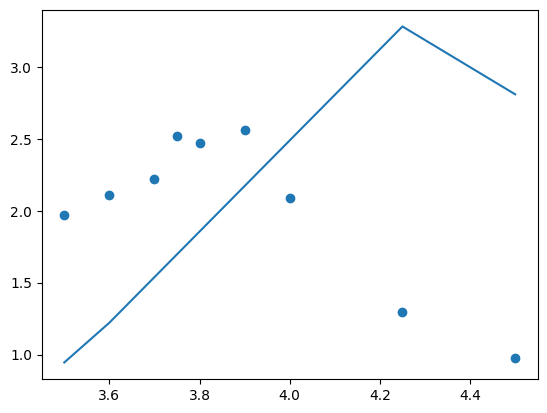

In [115]:
plt.figure()
plt.scatter(x_f,y_f)
plt.plot(x_f, trapezoid(x_f, *popt))
plt.errorbar(x_f,y_f, yerr=yerrs, fmt='none', ecolor='black', linewidth=0.5)

xx = np.linspace(x.min() - 0.2, x.max() + 0.2, 1000)
plt.errorbar(x, y, yerr=yerrs, fmt='o')
plt.plot(xx, trapezoid(xx, *popt))

plt.show()

In [60]:
yerrs.shape()

TypeError: 'tuple' object is not callable

In [81]:
# import numpy as np

# def trapezoid(x, x1, x2, x3, x4, h):
#     x = np.asarray(x, dtype=float)
#     conditions = [
#         x < x1,                      # before the rise: 0
#         (x >= x1) & (x < x2),        # rising edge
#         (x >= x2) & (x <= x3),       # flat top
#         (x > x3) & (x <= x4),        # falling edge
#         x > x4,                      # after the fall: 0
#     ]
#     functions = [
#         0.0,
#         lambda x: h * (x - x1) / (x2 - x1),
#         h,
#         lambda x: h * (x4 - x) / (x4 - x3),
#         0.0,
#     ]
#     return np.piecewise(x, conditions, functions)

# p0 = [0, 3.75, 3.95, 4.5]
# popt, pcov = curve_fit(trapezoid, x, y, p0=p0,
#                        sigma=yerrs, absolute_sigma=True)
# perr = np.sqrt(np.diag(pcov))

# import numpy as np
# from scipy.optimize import curve_fit

def trapezoid(x, x1, w_rise, w_top, w_fall, h):
    x2 = x1 + w_rise
    x3 = x2 + w_top
    x4 = x3 + w_fall
    x = np.asarray(x, dtype=float)
    conditions = [
        x < x1,
        (x >= x1) & (x < x2),
        (x >= x2) & (x <= x3),
        (x > x3) & (x <= x4),
        x > x4,
    ]
    functions = [
        lambda x: h * (x - x1) / w_rise,
        h,
        lambda x: h * (x4 - x) / w_fall,
        0.0,
    ]
    return np.piecewise(x, conditions, functions)

# initial guess from the data, not from guesswork
p0 = [3.5, 0.25, 0.2, 0.5, y.max()]          # x1, w_rise, w_top, w_fall, h
lower = [x.min(), 1e-3, 1e-3, 1e-3, 0]
upper = [x.max(), np.ptp(x), np.ptp(x), np.ptp(x), 2*y.max()]

popt, pcov = curve_fit(trapezoid, x, y, p0=p0, bounds=(lower, upper),
                       sigma=yerrs, absolute_sigma=True)

resid = (y - trapezoid(x, *popt)) / sigma
chi2 = np.sum(resid ** 2)
dof = len(y) - len(popt)          # now 5 parameters

print(chi2)
print(dof)

print(popt)

# import matplotlib.pyplot as plt

# x = np.linspace(-1, 10, 500)
# y = trapezoid(x, x1=2, x2=4, x3=6, x4=8, h=3)

# plt.plot(x, y)
# plt.show()

ValueError: with 5 condition(s), either 5 or 6 functions are expected

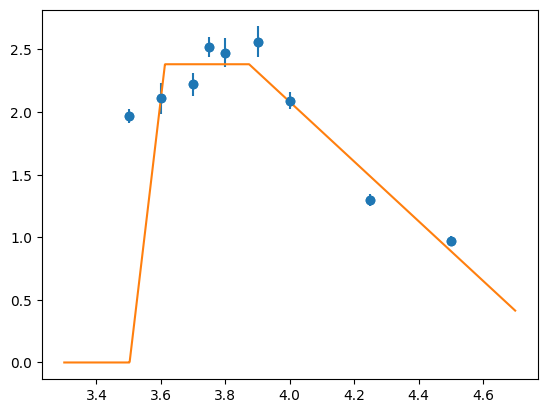

In [79]:
plt.figure()
plt.scatter(x,y)
# plt.plot(x, trapezoid(x, *popt))
# plt.errorbar(x,y, yerr=yerrs, fmt='none', ecolor='black', linewidth=0.5)

xx = np.linspace(x.min() - 0.2, x.max() + 0.2, 1000)
plt.errorbar(x, y, yerr=yerrs, fmt='o')
plt.plot(xx, trapezoid(xx, *popt))

plt.show()